# Stimulus-locked band power from Axo sleep EEG

This notebook computes the band power in three frequency bands **for each stimulus (trial)**, each within its specified time window before or after the stimulus, and then **averages across all trials**, so that each file yields **one value per frequency band**:

| Measure | Band | Time window relative to stimulus |
|---|---|---|
| Slow oscillation power | 0.5–1 Hz | −1.0 s to +2.0 s |
| Spindle power | 12–16 Hz | +1.0 s to +1.5 s |
| Delta power | 1–4 Hz | +0.25 s to +0.75 s |

**Method:** For each band, the continuous signal is filtered with a zero-phase FIR filter. The instantaneous power |analytic signal|² (µV²) is then computed with the Hilbert transform and averaged over the respective time window.

## 1. Setup and configuration

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.signal import hilbert
import mne
import matplotlib.pyplot as plt

mne.set_log_level("WARNING")

In [2]:
# ---- Paths ---------------------------------------------------------------
DATA_DIR = Path("data")              # folder containing the .mat (and optionally .edf) files
MAT_PATTERN = "*.mat"
OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True)

# ---- EEG source ------------------------------------------------------------
# "mat": EEG taken directly from the .mat (full resolution, no matching needed)
# "edf": EEG taken from the matching EDF; markers still come from the .mat
EEG_SOURCE = "mat"
CHANNEL = "FpZ"                      # FpZ = EEG_1; EOG1 = EEG_2; EOG2 = EEG_3; EMG1 = EEG_4; EMG2 = EEG_6

# Mapping EDF channel name -> column in M_HEA (verified on Axo072, identical sample for sample)
EDF_TO_MAT = {"FpZ": "EEG_1", "EOG1": "EEG_2", "EOG2": "EEG_3",
              "EMG1": "EEG_4", "ch5": "EEG_5", "EMG2": "EEG_6"}

SFREQ = 250.0                        # Hz (Axo device, per EDF header)

# ---- Markers ---------------------------------------------------------------
STIM_FLG_BIT = 8                     # Flg & 8 -> stimulus trigger
SILENT_VOLUME = -75                  # Volume == -75 -> no sound
CONDITIONS = ("audible", "silent")   # which triggers are computed per trial
AVERAGE_CONDITIONS = ("audible",)    # which trials enter the average
                                     # (stimulus = sound; use ("audible", "silent") for all triggers)
AVERAGE_STAT = "mean"                # "mean" or "median" across trials

# ---- Artifact criteria (flagging only, nothing is deleted) -------------------
RAIL_UV = 187_000                    # amplifier saturation (range ±187 500 µV)
PTP_MAX_UV = 500                     # max. peak-to-peak of the 0.3-30 Hz signal, -1 to +2 s

### Power bands and time windows
The filter transition bandwidths are set explicitly on purpose: with MNE's defaults, the 0.5–1 Hz filter, for example, would only reach its stop band at 3 Hz and let a lot of delta activity through.

In [3]:
BANDS = {
    #  name           (f_low, f_high)  window (s)      transition bandwidth (low, high) in Hz
    "so_power":      dict(band=(0.5, 1.0), window=(-1.0, 2.0), trans=(0.25, 0.25)),
    "spindle_power": dict(band=(12., 16.), window=(1.0, 1.5),  trans=(2.0, 2.0)),
    "delta_power":   dict(band=(1.0, 4.0), window=(0.25, 0.75), trans=(0.5, 0.5)),
}
pd.DataFrame({k: {"Band (Hz)": f"{v['band'][0]}–{v['band'][1]}",
                  "Window (s)": f"{v['window'][0]:+} to {v['window'][1]:+}",
                  "Transitions (Hz)": v["trans"]} for k, v in BANDS.items()}).T

,Band (Hz),Window (s),Transitions (Hz)
so_power,0.5–1.0,-1.0 to +2.0,"(0.25, 0.25)"
spindle_power,12.0–16.0,+1.0 to +1.5,"(2.0, 2.0)"
delta_power,1.0–4.0,+0.25 to +0.75,"(0.5, 0.5)"


## 2. Functions: loading data and markers

In [4]:
def load_mat(path):
    """Load an Axo .mat file. Returns (header list, M_VAL matrix, RECORDER struct)."""
    d = sio.loadmat(path, variable_names=["M_HEA", "M_VAL", "RECORDER"],
                    squeeze_me=True, struct_as_record=False)
    header = [str(h) for h in np.atleast_1d(d["M_HEA"])]
    return header, d["M_VAL"], d.get("RECORDER")


def col(header, name):
    """Index of the first column with this name (EEG_TimeStamps appears twice)."""
    return header.index(name)


def find_stimuli(header, M):
    """Find all stimulus triggers (onset of Flg & 8) and classify them."""
    flg = M[:, col(header, "Flg")].astype(np.int64)
    vol = M[:, col(header, "Volume")]
    is_trig = (flg & STIM_FLG_BIT) > 0
    onsets = np.flatnonzero(np.diff(np.r_[0, is_trig.astype(np.int8)]) == 1)
    volume = vol[onsets]
    cond = np.where(volume > SILENT_VOLUME, "audible", "silent")
    return pd.DataFrame({"sample": onsets,
                         "time_s": onsets / SFREQ,
                         "condition": cond,
                         "volume_db": volume})


def get_eeg(mat_path, header, M, channel=CHANNEL):
    """EEG channel in µV, from the .mat or from the matching EDF."""
    if EEG_SOURCE == "mat":
        return M[:, col(header, EDF_TO_MAT[channel])].astype(float)
    # matching EDF: same timestamp in the file name (e.g. 20260201_222725_000078)
    stamp = re.search(r"\d{8}_\d{6}_\d+", mat_path.name).group(0)
    edf = next(mat_path.parent.glob(f"*{stamp}*.edf"))
    raw = mne.io.read_raw_edf(edf, include=[channel], preload=True)
    x = raw.get_data()[0] * 1e6
    return x[: M.shape[0]]           # EDF is padded to full 1-s records

## 3. Functions: band power

In [5]:
def band_envelope_power(x, band, trans, sfreq=SFREQ):
    """Zero-phase FIR band-pass on the continuous signal, then |Hilbert|² (µV²)."""
    xf = mne.filter.filter_data(x[np.newaxis], sfreq, band[0], band[1],
                                l_trans_bandwidth=trans[0], h_trans_bandwidth=trans[1],
                                method="fir", phase="zero", fir_design="firwin",
                                verbose=False)[0]
    return np.abs(hilbert(xf)) ** 2


def window_mean(power, samples, window, sfreq=SFREQ):
    """Mean of `power` in the window [t0, t1) around each sample; NaN if outside the recording."""
    i0, i1 = int(round(window[0] * sfreq)), int(round(window[1] * sfreq))
    out = np.full(len(samples), np.nan)
    for k, s in enumerate(samples):
        a, b = s + i0, s + i1
        if a >= 0 and b <= len(power):
            out[k] = power[a:b].mean()
    return out


def artifact_flags(x, samples, sfreq=SFREQ, window=(-1.0, 2.0)):
    """Flag trials with saturation or excessive amplitude (peak-to-peak)."""
    xb = mne.filter.filter_data(x[np.newaxis], sfreq, 0.3, 30., verbose=False)[0]
    i0, i1 = int(window[0] * sfreq), int(window[1] * sfreq)
    rail, ptp = np.zeros(len(samples), bool), np.full(len(samples), np.nan)
    for k, s in enumerate(samples):
        a, b = max(s + i0, 0), min(s + i1, len(x))
        rail[k] = np.any(np.abs(x[a:b]) >= RAIL_UV)
        ptp[k] = np.ptp(xb[a:b])
    return rail, ptp, xb

## 4. Per file: find markers and extract band power

In [6]:
def process_file(mat_path):
    header, M, rec = load_mat(mat_path)
    stim = find_stimuli(header, M)
    stim = stim[stim["condition"].isin(CONDITIONS)].reset_index(drop=True)
    x = get_eeg(mat_path, header, M)
    del M                                                   # free memory (~1.3 GB)

    for name, cfg in BANDS.items():
        p = band_envelope_power(x, cfg["band"], cfg["trans"])
        stim[name] = window_mean(p, stim["sample"].to_numpy(), cfg["window"])

    rail, ptp, xb = artifact_flags(x, stim["sample"].to_numpy())
    stim["rail_clipped"] = rail
    stim["ptp_uv"] = ptp
    stim["reject"] = rail | (ptp > PTP_MAX_UV)
    stim.insert(0, "trial", np.arange(len(stim)))
    stim.insert(0, "file", mat_path.stem)
    stim.insert(1, "channel", CHANNEL)
    return stim, xb


mat_files = sorted(DATA_DIR.glob(MAT_PATTERN))
print(f"{len(mat_files)} .mat file(s) found")

all_trials, bb_signals = [], {}
for f in mat_files:
    df, xb = process_file(f)
    all_trials.append(df)
    bb_signals[f.stem] = xb                                 # for the plots below
    n = df["condition"].value_counts().to_dict()
    print(f"{f.name}: {len(df)} triggers {n}, rejected: {df['reject'].sum()}")

trials = pd.concat(all_trials, ignore_index=True)
trials.to_csv(OUT_DIR / "bandpower_per_trial.csv", index=False)
trials.head()

1 .mat file(s) found


33-54-23-13-A2-FD_Axo072_20260201_222725_000078.mat: 3350 triggers {'silent': 1710, 'audible': 1640}, rejected: 13


,file,channel,trial,sample,time_s,condition,volume_db,so_power,spindle_power,delta_power,rail_clipped,ptp_uv,reject
0,33-54-23-13-A2-FD_Axo072_20260201_222725_000078,FpZ,0,603487,2413.948,audible,-63.0,1567.173764,21.261425,4206.705458,False,194.893818,False
1,33-54-23-13-A2-FD_Axo072_20260201_222725_000078,FpZ,1,603712,2414.848,audible,-63.0,1407.032953,9.925044,615.649015,False,213.528986,False
2,33-54-23-13-A2-FD_Axo072_20260201_222725_000078,FpZ,2,603988,2415.952,audible,-63.0,2148.842309,4.157681,4639.894999,False,213.528986,False
3,33-54-23-13-A2-FD_Axo072_20260201_222725_000078,FpZ,3,604138,2416.552,audible,-63.0,3050.922012,20.067794,2350.774863,False,232.700869,False
4,33-54-23-13-A2-FD_Axo072_20260201_222725_000078,FpZ,4,606057,2424.228,audible,-61.0,1674.741925,41.711842,6100.694003,False,200.787590,False


## 5. Average across trials: one value per frequency band
Artifact trials (`reject`) are excluded. The average is taken over the trials of the conditions listed in `AVERAGE_CONDITIONS`.
Result: one row per file, one column per frequency band (µV²), plus the number of trials included.

In [7]:
power_cols = list(BANDS)
clean = trials[~trials["reject"]]
avg_trials = clean[clean["condition"].isin(AVERAGE_CONDITIONS)]

band_means = avg_trials.groupby(["file", "channel"])[power_cols].agg(AVERAGE_STAT)
band_means.insert(0, "n_trials", avg_trials.groupby(["file", "channel"]).size())
band_means.columns = ["n_trials"] + [
    f"{c} ({BANDS[c]['band'][0]}-{BANDS[c]['band'][1]} Hz, "
    f"{BANDS[c]['window'][0]:+}..{BANDS[c]['window'][1]:+} s) [µV²]" for c in power_cols]
band_means.to_csv(OUT_DIR / "bandpower_mean_per_file.csv")
print(f"Averaged ({AVERAGE_STAT}) over conditions: {AVERAGE_CONDITIONS}")
band_means.T

Averaged (mean) over conditions: ('audible',)


file,33-54-23-13-A2-FD_Axo072_20260201_222725_000078
channel,FpZ
n_trials,1635.000000
"so_power (0.5-1.0 Hz, -1.0..+2.0 s) [µV²]",1777.178433
"spindle_power (12.0-16.0 Hz, +1.0..+1.5 s) [µV²]",9.134507
"delta_power (1.0-4.0 Hz, +0.25..+0.75 s) [µV²]",1937.970619


For comparison, the same average split by condition (audible vs. silent):

In [8]:
by_cond = clean.groupby(["file", "condition"])[power_cols].agg(AVERAGE_STAT)
by_cond.insert(0, "n_trials", clean.groupby(["file", "condition"]).size())
by_cond

n_trials  \
file                                            condition             
33-54-23-13-A2-FD_Axo072_20260201_222725_000078 audible        1635   
                                                silent         1702   

                                                              so_power  \
file                                            condition                
33-54-23-13-A2-FD_Axo072_20260201_222725_000078 audible    1777.178433   
                                                silent      786.332870   

                                                           spindle_power  \
file                                            condition                  
33-54-23-13-A2-FD_Axo072_20260201_222725_000078 audible         9.134507   
                                                silent          5.647731   

                                                           delta_power  
file                                            condition               
33-54-23-13-A2-FD_Axo072_20260201_222725_000078 audible    1937.970619  
                                                silent      513.546756

## 6. Sanity checks
**a) Event-related potential (ERP).** With closed-loop stimulation in the slow-oscillation up-phase, the signal should be positive shortly before the stimulus (up-phase), followed by another slow oscillation.

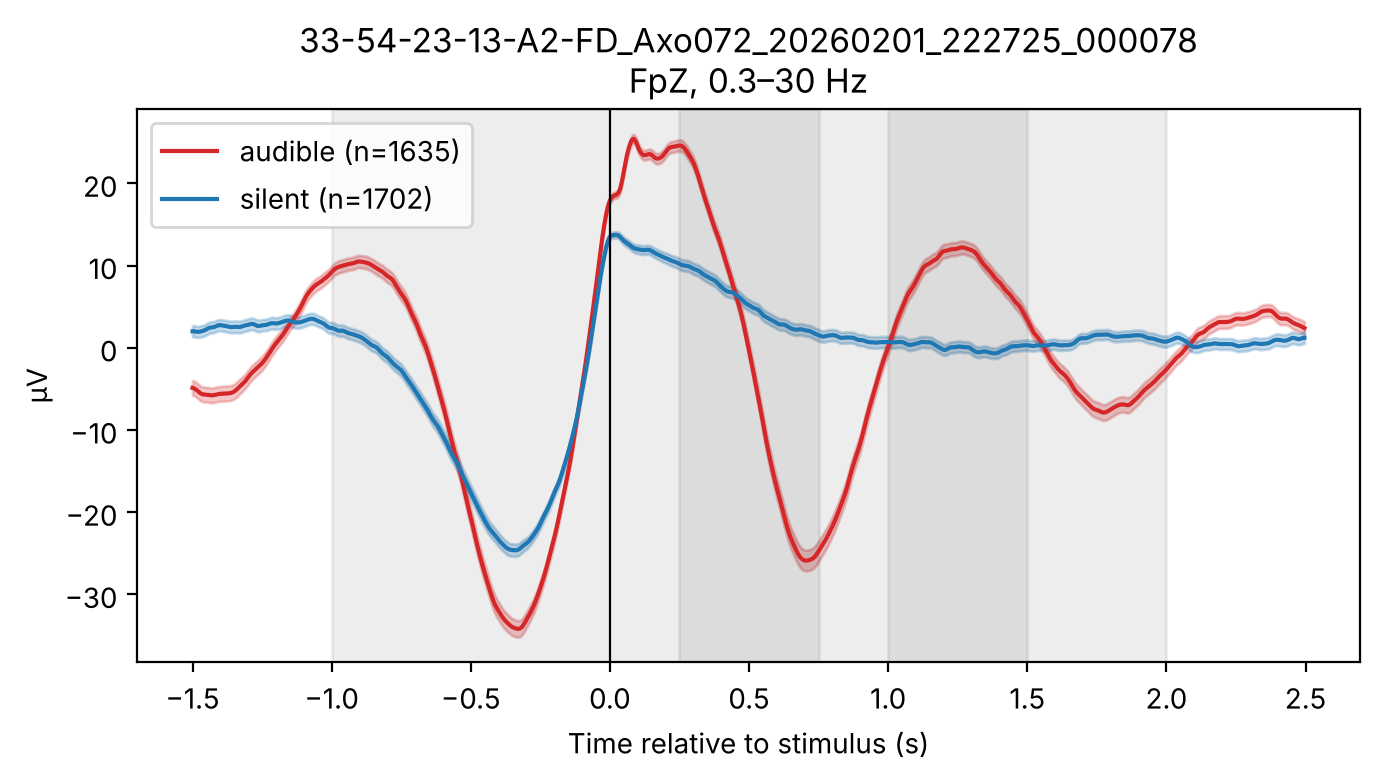

In [9]:
def epochs(x, samples, tmin=-1.5, tmax=2.5, sfreq=SFREQ):
    i0, i1 = int(tmin * sfreq), int(tmax * sfreq)
    keep = [s for s in samples if s + i0 >= 0 and s + i1 <= len(x)]
    return np.stack([x[s + i0:s + i1] for s in keep]), np.arange(i0, i1) / sfreq

fig, axes = plt.subplots(1, len(bb_signals), figsize=(7 * len(bb_signals), 4), squeeze=False)
for ax, (stem, xb) in zip(axes[0], bb_signals.items()):
    df = clean[clean["file"] == stem]
    for cond, color in [("audible", "C3"), ("silent", "C0")]:
        s = df.loc[df["condition"] == cond, "sample"].to_numpy()
        if len(s) == 0:
            continue
        ep, t = epochs(xb, s)
        m, se = ep.mean(0), ep.std(0) / np.sqrt(len(ep))
        ax.plot(t, m, color=color, label=f"{cond} (n={len(ep)})")
        ax.fill_between(t, m - se, m + se, color=color, alpha=0.25)
    for name, cfg in BANDS.items():
        ax.axvspan(*cfg["window"], alpha=0.07, color="k")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"{stem}\n{CHANNEL}, 0.3–30 Hz", xlabel="Time relative to stimulus (s)", ylabel="µV")
    ax.legend()
plt.tight_layout(); plt.show()

**b) Distribution of band power per condition** (log scale, since power is strongly right-skewed).

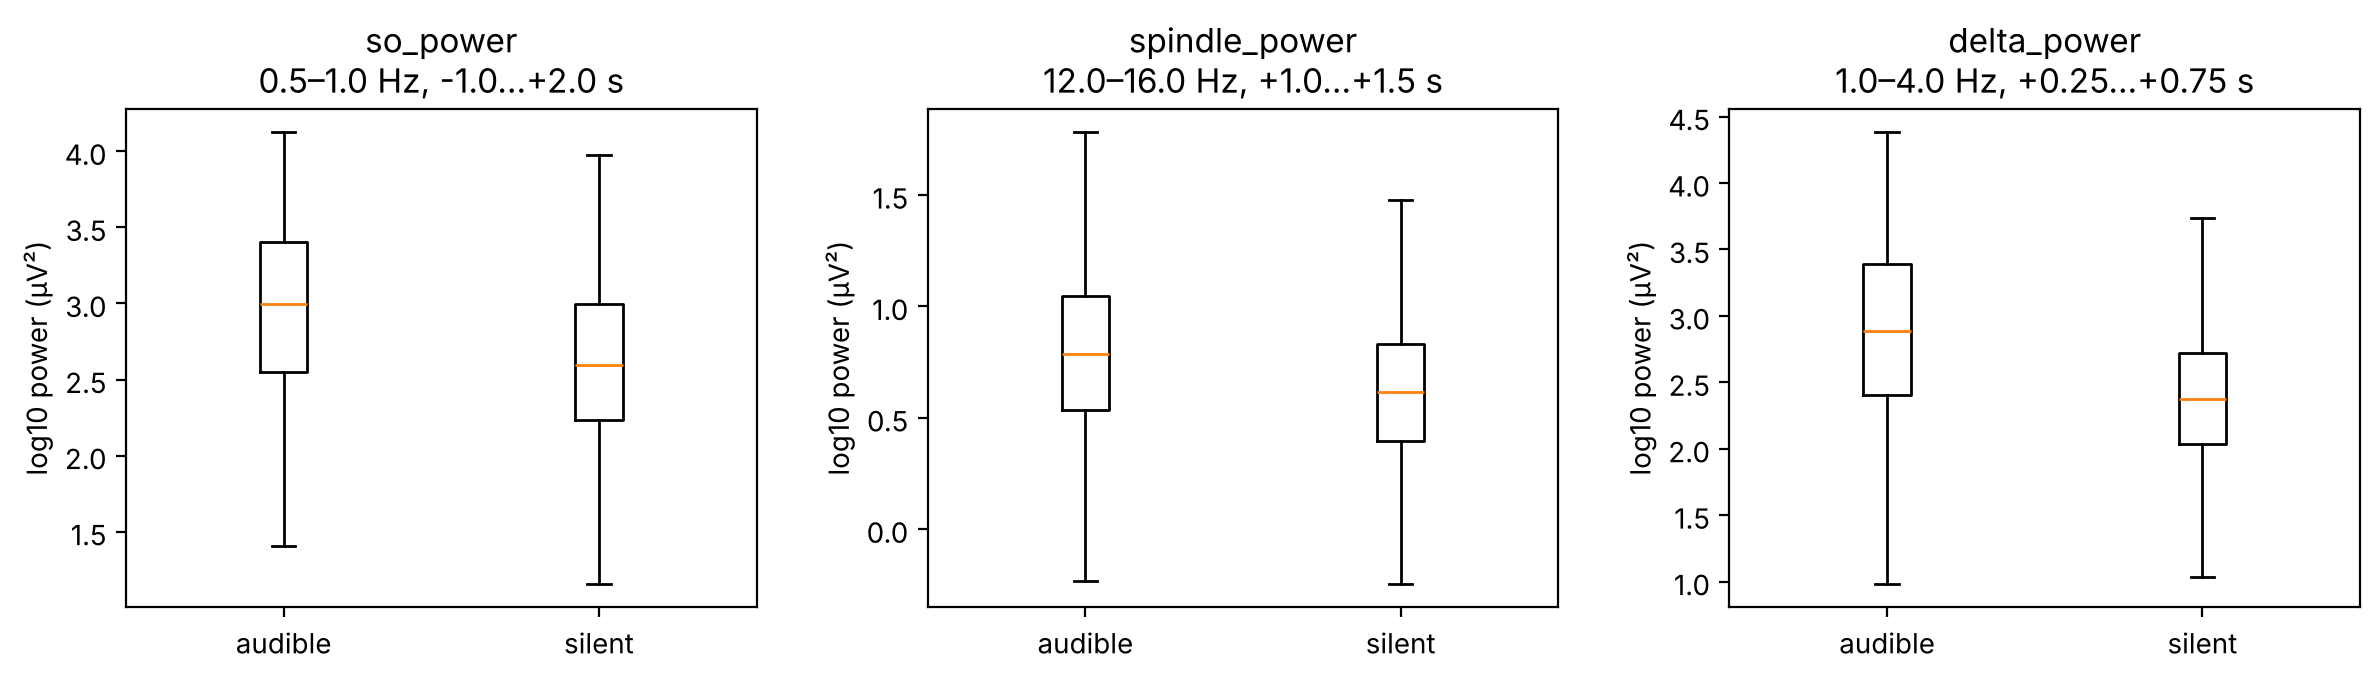

In [10]:
fig, axes = plt.subplots(1, len(power_cols), figsize=(4 * len(power_cols), 3.5))
for ax, c in zip(axes, power_cols):
    data = [np.log10(clean.loc[clean["condition"] == k, c].dropna()) for k in CONDITIONS]
    ax.boxplot(data, tick_labels=CONDITIONS, showfliers=False)
    cfg = BANDS[c]
    ax.set(title=f"{c}\n{cfg['band'][0]}–{cfg['band'][1]} Hz, {cfg['window'][0]:+}…{cfg['window'][1]:+} s",
           ylabel="log10 power (µV²)")
plt.tight_layout(); plt.show()

**c) When during the night did the triggers occur?** Important for interpretation: comparing `audible` vs. `silent` is only fair if both conditions are spread across the night.

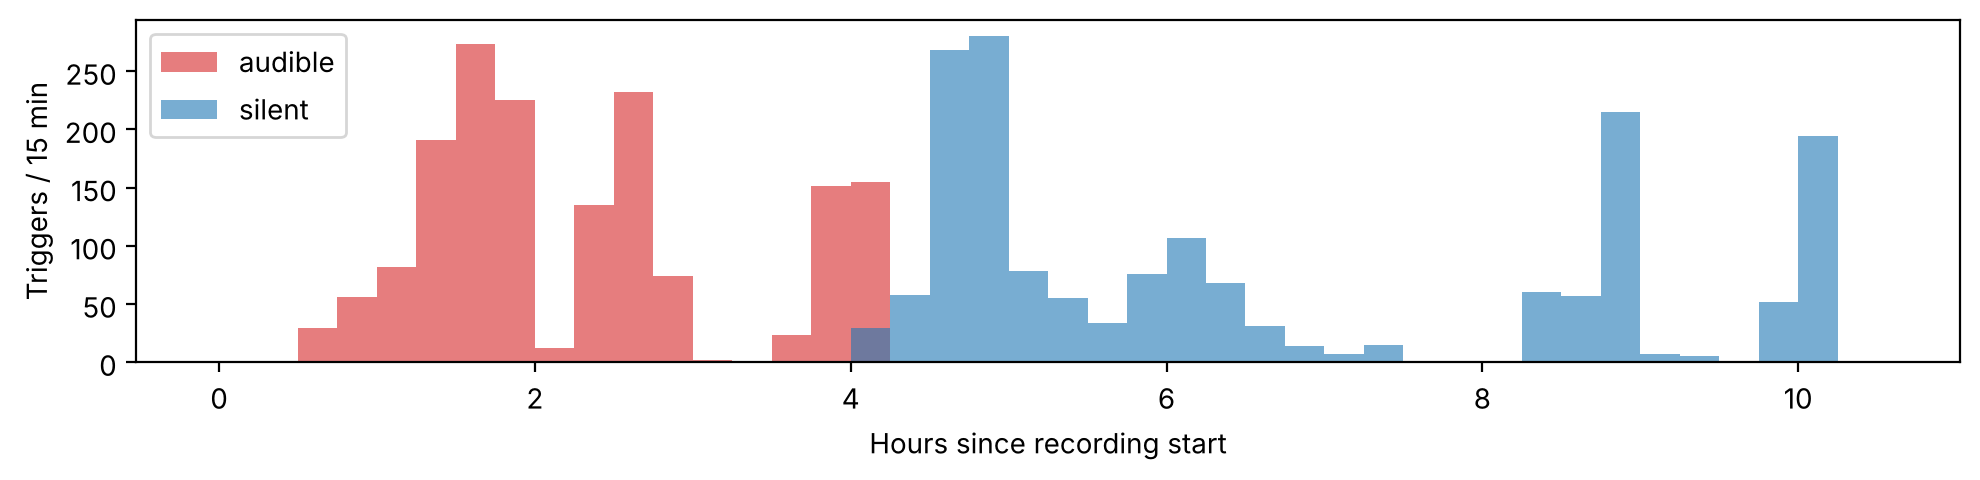

In [11]:
fig, ax = plt.subplots(figsize=(10, 2.5))
for cond, color in [("audible", "C3"), ("silent", "C0")]:
    s = trials.loc[trials["condition"] == cond, "time_s"] / 3600
    ax.hist(s, bins=np.arange(0, s.max() + 0.5 if len(s) else 1, 0.25), color=color, alpha=0.6, label=cond)
ax.set(xlabel="Hours since recording start", ylabel="Triggers / 15 min"); ax.legend()
plt.tight_layout(); plt.show()